# Play Tic-Tac-Toe Interactively (Simple Implementation)

To play interactively, you need to run the whole notebook in JupyterLab and scroll down.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

## Implement an Interactive Game


### Interactive Player

Implement the interactive player. It shows the board and asks you for the move.

In [3]:
from IPython.display import clear_output

def interactive_player(board, player = None):
    clear_output(wait = False)
    show_board(board, help = True)
    
    available = actions(board)
    print(f'Available actions are: {available}')

    retry = True
    while retry:
        try:
            move = int(input("Your move (0-8 or -1 to end the game):\n"))            
        
            if move in available:
                retry = False
            else:
                raise ValueError()
        except ValueError:
            if move == -1:
                print("Game ended by user.")
                raise Exception("Game ended by user.")
            
            print("Please enter a valid move.")
            

    return(move)

## Start an interactive game as x

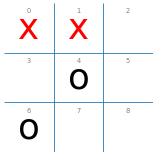

Available actions are: [2, 3, 5, 7, 8]


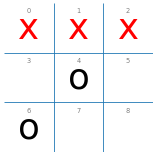

{'x': 1, 'o': 0, 'd': 0}

In [4]:
play(interactive_player, random_player, N = 1,  show_final_board=True)

### Start an interactive game as o

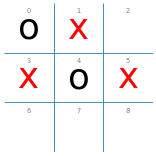

Available actions are: [2, 6, 7, 8]


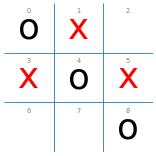

{'x': 0, 'o': 1, 'd': 0}

In [5]:
play(random_player, interactive_player, N = 1, show_final_board = True)

## Chơi với tác tử UCB1
Phần dưới đây dùng tác tử UCB1 (100 playout) của Bài 6 làm đối thủ và ghi lại danh sách nước đi của mỗi ván.

In [6]:
# Tác tử UCB1 lấy từ notebook Bài 6 (tictactoe_monte_carlo_tree_search_restricted.ipynb)
import numpy as np

def playout(state, action, player = 'x'):
    """Perform a random playout starting with the given action on the given board 
    and return the utility of the finished game."""
    state = result(state, player, action)
    current_player = other(player)
    
    while(True):
        # reached terminal state?
        u = utility(state, player)
        if u is not None: 
            return u
        
        # we use a random playout policy
        a = np.random.choice(actions(state))
        state = result(state, current_player, a)
        #print(state)
        
        # switch between players
        current_player = other(current_player)


import pandas as pd
import math

DEBUG = 0

def UCT_depth1(board, N = 100, player = 'x'):
    """Upper Confidence bound applied to Trees for limited tree depth of 1. 
    Simulation budget is N playouts."""
    global DEBUG
    
    C = math.sqrt(2) # tradeoff constant
    
    # the tree is 1 action deep
    acts = actions(board)
    
    u = [0] * len(acts) # total utility through actions
    n = [0] * len(acts) # number of playouts through actions
    n_parent = 0 # total playouts so far (i.e., number of playouts through parent)
    
    # make sure we try each action once
    UCB1 = [+math.inf] * len(acts) 
    
    for i in range(N):

        # Select
        action_id = UCB1.index(max(UCB1))
    
        # Expand
        # UTC would expand the tree. We keep the tree at depth 1, essentially performing
        # Pure Monte Carlo search with an added UCB1 selection policy. 
        
        # Simulate
        p = playout(board, acts[action_id], player = player)
    
        # Back-Propagate (i.e., update counts and UCB1)
        u[action_id] += p
        n[action_id] += 1
        n_parent += 1
        
        for action_id in range(len(acts)):
            if n[action_id] > 0:
                UCB1[action_id] = u[action_id] / n[action_id] + C * math.sqrt(math.log(n_parent) / n[action_id])
    
    # return action with largest number of playouts 
    action = acts[n.index(max(n))]
    
    if DEBUG >= 1: 
        print(pd.DataFrame({'action':acts, 
                            'total utility':u, 
                            '# of playouts':n, 
                            'UCB1':UCB1}))
        print()
        print(f"Best action: {action}")
    
    
    return action

def ucb1_10_player(board, player = 'x'):
    action = UCT_depth1(board, N = 10, player = player)
    return action

def ucb1_100_player(board, player = 'x'):
    action = UCT_depth1(board, N = 100, player = player)
    return action

### Ghi lại nước đi

In [7]:
game_log = []   # ghi lại mọi nước đi: (ai đi, quân, ô)

def logged(agent, name):
    """Bọc một tác tử để ghi lại các nước đi của nó vào game_log."""
    def wrapper(board, player = None):
        move = agent(board, player)
        game_log.append((name, player, int(move)))
        return move
    return wrapper

def show_log(result):
    print("Kết quả:", result, "(x = người đi trước, o = người đi sau, d = hòa)")
    print("Các nước đi theo thứ tự:")
    for k, (name, p, m) in enumerate(game_log, 1):
        print(f"  {k}. {name} ({p}) đi ô {m}")

### Ván 1: bạn đi trước (x)
Nhập số ô (0–8) vào hộp thoại nhập ở **đầu cửa sổ VS Code**, rồi nhấn Enter. Nhập -1 để dừng ván.

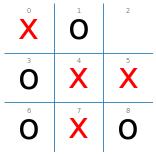

Available actions are: [2]


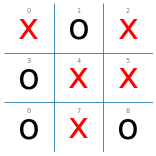

Kết quả: {'x': 0, 'o': 0, 'd': 1} (x = người đi trước, o = người đi sau, d = hòa)
Các nước đi theo thứ tự:
  1. Bạn (x) đi ô 0
  2. UCB1 (o) đi ô 6
  3. Bạn (x) đi ô 4
  4. UCB1 (o) đi ô 8
  5. Bạn (x) đi ô 7
  6. UCB1 (o) đi ô 1
  7. Bạn (x) đi ô 5
  8. UCB1 (o) đi ô 3
  9. Bạn (x) đi ô 2


In [8]:
# Ván 1: BẠN đi trước (x), UCB1 (100) đi sau (o)
game_log.clear()
res = play(logged(interactive_player, "Bạn"), logged(ucb1_100_player, "UCB1"), N = 1, show_final_board = True)
show_log(res)

### Ván 2: bạn đi sau (o)

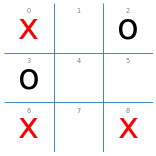

Available actions are: [1, 4, 5, 7]


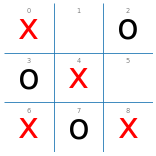

Kết quả: {'x': 1, 'o': 0, 'd': 0} (x = người đi trước, o = người đi sau, d = hòa)
Các nước đi theo thứ tự:
  1. UCB1 (x) đi ô 0
  2. Bạn (o) đi ô 2
  3. UCB1 (x) đi ô 6
  4. Bạn (o) đi ô 3
  5. UCB1 (x) đi ô 8
  6. Bạn (o) đi ô 7
  7. UCB1 (x) đi ô 4


In [9]:
# Ván 2: UCB1 (100) đi trước (x), BẠN đi sau (o)
game_log.clear()
res = play(logged(ucb1_100_player, "UCB1"), logged(interactive_player, "Bạn"), N = 1, show_final_board = True)
show_log(res)